# Fake Job Posting Detection

## Dataset Understanding

In this notebook, we will:

- Load the dataset
- Explore the dataset
- Understand every feature
- Identify missing values
- Check duplicates

### Importing Required Libraries

In [18]:
import pandas as pd
import numpy as np

### Load the Dataset

In [19]:
df = pd.read_csv("../data/fake_job_postings.csv")

df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [20]:
# Check Dataset Shape

df.shape

(17880, 18)

In [21]:
# Check Columns Names

df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')

# Phase 2 - Dataset Information

In this phase, we will:

- Understand every feature
- Identify data types
- Check memory usage
- Understand the target variable

In [22]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [6]:
# Check missing values

missing_values = df.isnull().sum()

missing_values

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

### Sort Missing Values

In [23]:

missing_values.sort_values(ascending=False)

salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64

### Missing Percentage

In [24]:
missing_percentage = (df.isnull().sum() / len(df))* 100


# Sort missing percentage
missing_percentage.sort_values(ascending=False)

salary_range           83.959732
department             64.580537
required_education     45.329978
benefits               40.335570
required_experience    39.429530
function               36.101790
industry               27.421700
employment_type        19.412752
company_profile        18.501119
requirements           15.078300
location                1.935123
description             0.005593
title                   0.000000
job_id                  0.000000
telecommuting           0.000000
has_questions           0.000000
has_company_logo        0.000000
fraudulent              0.000000
dtype: float64

In [9]:
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

missing_table.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Percentage
salary_range,15012,83.959732
department,11547,64.580537
required_education,8105,45.329978
benefits,7212,40.335570
required_experience,7050,39.429530
function,6455,36.101790
industry,4903,27.421700
employment_type,3471,19.412752
company_profile,3308,18.501119
requirements,2696,15.078300


### Visualize Missing Values

<function matplotlib.pyplot.show(close=None, block=None)>

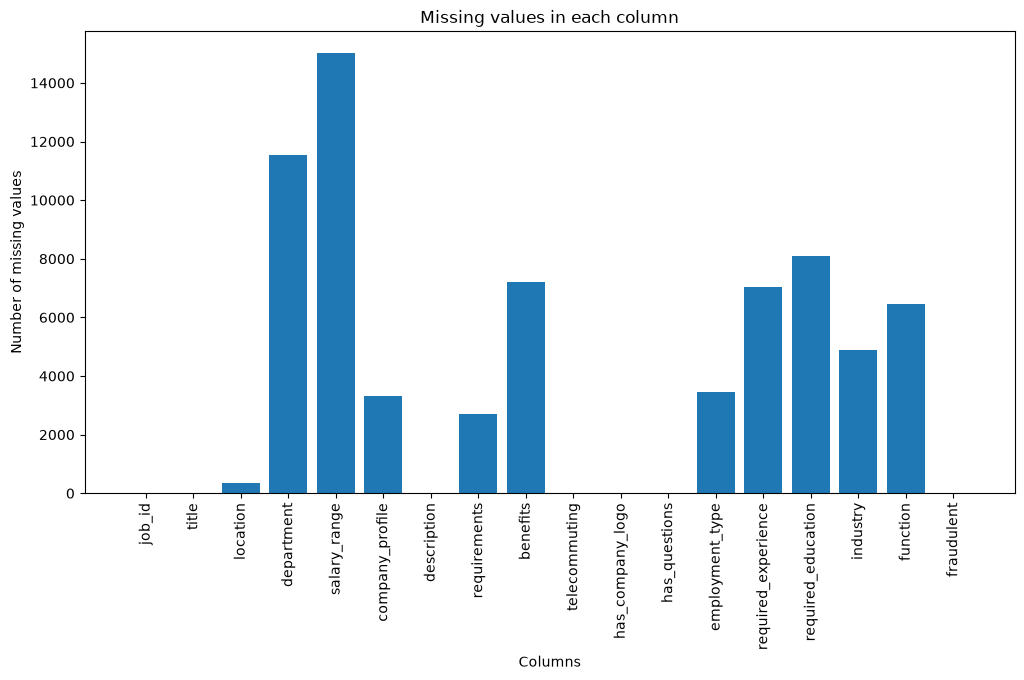

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.bar(
    missing_table.index,
    missing_table["Missing Values"]
)


plt.xticks(rotation=90)

plt.title("Missing values in each column")

plt.xlabel("Columns")

plt.ylabel("Number of missing values")

plt.show

In [26]:
missing_table

,Missing Values,Percentage
job_id,0,0.000000
title,0,0.000000
location,346,1.935123
department,11547,64.580537
salary_range,15012,83.959732
company_profile,3308,18.501119
description,1,0.005593
requirements,2696,15.078300
benefits,7212,40.335570
telecommuting,0,0.000000


### Fill Missing Values

In [27]:
# Fill missing values in all text columns

text_columns = [
    "location",
    "department",
    "salary_range",
    "company_profile",
    "description",
    "requirements",
    "benefits",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

df[text_columns] = df[text_columns].fillna("")

In [13]:
df.isnull().sum()

job_id                 0
title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17880 non-null  str  
 3   department           17880 non-null  str  
 4   salary_range         17880 non-null  str  
 5   company_profile      17880 non-null  str  
 6   description          17880 non-null  str  
 7   requirements         17880 non-null  str  
 8   benefits             17880 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      17880 non-null  str  
 13  required_experience  17880 non-null  str  
 14  required_education   17880 non-null  str  
 15  industry             17880 non-null  str  
 16  function             17880 non-nu

### Count Duplicates Rows

In [29]:
duplicates = df.duplicated().sum()

print("The Number of Duplicate Rows are : ",duplicates)

The Number of Duplicate Rows are :  0


In [30]:
# Check dataset shape again

df.shape

(17880, 18)

In [31]:
# Save cleaned dataset
df.to_csv("../data/cleaned_fake_job_postings.csv", index=False)

print("✅ Cleaned dataset saved successfully!")

✅ Cleaned dataset saved successfully!
